# Precipitation and water quality: fitting the formula

The goal: given how much it has rained recently, estimate the probability that a beach's E. coli reading will exceed Toronto's safety standard (100 E.coli / 100mL).

```
data/Toronto Daily Weather/*.csv   ->  daily rainfall, 2007-2026
data/Toronto EColi Data/torontowater.csv  ->  daily E. coli readings, 2007-2026
                                   \->  this notebook  ->  a fitted logistic regression
```

This is the same approach beach-advisory systems like EPA's Virtual Beach and Chicago's nowcast model use: **antecedent rainfall** (how much rain fell in the day(s) before sampling) as the predictor, and **logistic regression** predicting the probability of exceeding the bacterial standard, rather than trying to predict the exact E. coli count (which is far noisier).

## Part 1. Load the rainfall data

Environment and Climate Change Canada splits daily data into one file per year. Each file has the same columns, so we read all 20 and stack them with `pd.concat`.

`usecols` keeps only the columns we need, but it **does not preserve the order you ask for** — it returns columns in the order they appear in the file. Renaming has to match the file's order, not the order written in `usecols`, or the columns get mislabeled.

In [1]:
import glob
import pandas as pd
import numpy as np

files = sorted(glob.glob("../data/Toronto Daily Weather/*.csv"))
print(len(files), "weather files found")

weather = pd.concat(
    [pd.read_csv(f, encoding="utf-8-sig", usecols=["Date/Time", "Total Precip (mm)"]) for f in files],
    ignore_index=True,
)
weather = weather.rename(columns={"Date/Time": "date", "Total Precip (mm)": "precip_mm"})
weather["date"] = pd.to_datetime(weather["date"])
weather = weather.sort_values("date").drop_duplicates("date").reset_index(drop=True)

print("rows:", len(weather))
print("date range:", weather["date"].min().date(), "to", weather["date"].max().date())
print("missing precip readings:", weather["precip_mm"].isna().sum(), "/", len(weather))
weather.head()

20 weather files found
rows: 7305
date range: 2007-01-01 to 2026-12-31
missing precip readings: 247 / 7305


,date,precip_mm
0,2007-01-01,0.0
1,2007-01-02,0.0
2,2007-01-03,0.0
3,2007-01-04,3.2
4,2007-01-05,6.4


## Part 2. Antecedent rainfall

A beach doesn't get contaminated by the rain falling *during* the sample collection — it's the rain from the day(s) **before** that washes bacteria into the water. Two features:

- `rain_1d`: precipitation on the day before the reading
- `rain_3d`: total precipitation over the 3 days before the reading

Both are built with `.shift(1)` so the sampling day itself is excluded — `rolling(3).sum()` on its own would include the current day.

In [3]:
weather = weather.set_index("date")

full_range = pd.date_range(weather.index.min(), weather.index.max(), freq="D")
assert len(full_range) == len(weather), "there's a gap in the daily weather record"

weather["rain_1d"] = weather["precip_mm"].shift(1)
weather["rain_3d"] = weather["precip_mm"].rolling(3).sum().shift(1)
weather = weather.reset_index()

weather[["date", "precip_mm", "rain_1d", "rain_3d"]].dropna().head()

,date,precip_mm,rain_1d,rain_3d
3,2007-01-04,3.2,0.0,0.0
4,2007-01-05,6.4,3.2,3.2
5,2007-01-06,5.0,6.4,9.6
6,2007-01-07,0.8,5.0,14.6
7,2007-01-08,1.8,0.8,12.2


## Part 3. One E. coli reading per beach per day

Same cleaning as `beach_quality.ipynb`: parse the dates, drop samples with no E. coli result, then average the sampling sites at each beach into one daily number per beach. A beach is flagged `unsafe` for that day if its average exceeds Toronto's 100 E.coli/100mL standard.

In [4]:
df = pd.read_csv("../data/Toronto EColi Data/torontowater.csv")
df["collectionDate"] = pd.to_datetime(df["collectionDate"])

readings = df.dropna(subset=["eColi"]).copy()

daily = readings.groupby(["beachId", "beachName", "collectionDate"], as_index=False).agg(
    avg_eColi=("eColi", "mean"),
    n_readings=("eColi", "size"),
)
daily["unsafe"] = (daily["avg_eColi"] > 100).astype(int)

print("beach-days:", len(daily))
print(daily["unsafe"].value_counts(normalize=True).rename("share"))
daily.head()

beach-days: 19790
unsafe
0    0.817079
1    0.182921
Name: share, dtype: float64


,beachId,beachName,collectionDate,avg_eColi,n_readings,unsafe
0,1,Marie Curtis Park East Beach,2007-06-03,10.0,5,0
1,1,Marie Curtis Park East Beach,2007-06-04,1614.0,5,1
2,1,Marie Curtis Park East Beach,2007-06-05,22.0,5,0
3,1,Marie Curtis Park East Beach,2007-06-06,46.0,5,0
4,1,Marie Curtis Park East Beach,2007-06-07,420.0,5,1


## Part 4. Join readings to the rainfall that preceded them

Every beach samples on the same day share Toronto's one rainfall record, so this is a simple merge on date — no per-beach geometry needed here.

In [5]:
merged = daily.merge(weather[["date", "rain_1d", "rain_3d"]], left_on="collectionDate", right_on="date", how="left")

print("beach-days with no matching weather date:", merged["date"].isna().sum())

model_df = merged.dropna(subset=["rain_1d", "rain_3d"]).copy()
print("rows with complete rainfall history:", len(model_df), "/", len(merged))
model_df.head()

beach-days with no matching weather date: 0
rows with complete rainfall history: 18763 / 19790


,beachId,beachName,collectionDate,avg_eColi,n_readings,unsafe,date,rain_1d,rain_3d
0,1,Marie Curtis Park East Beach,2007-06-03,10.0,5,0,2007-06-03,0.0,1.7
1,1,Marie Curtis Park East Beach,2007-06-04,1614.0,5,1,2007-06-04,9.1,9.1
2,1,Marie Curtis Park East Beach,2007-06-05,22.0,5,0,2007-06-05,2.0,11.1
3,1,Marie Curtis Park East Beach,2007-06-06,46.0,5,0,2007-06-06,1.8,12.9
4,1,Marie Curtis Park East Beach,2007-06-07,420.0,5,1,2007-06-07,0.0,3.8


## Part 5. A first look, before modelling

Bucket the readings by how much rain fell in the prior 3 days and check the share flagged `unsafe` in each bucket. If the idea holds up, the share should climb with the rain.

rain_3d_bucket
0mm        0.126055
0-5mm      0.140039
5-15mm     0.206005
15-30mm    0.292537
30mm+      0.440466
Name: unsafe, dtype: float64


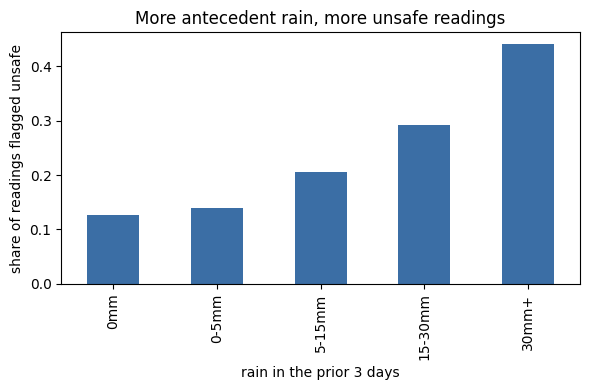

In [6]:
import matplotlib.pyplot as plt

bucket_edges = [-0.1, 0, 5, 15, 30, 1000]
bucket_labels = ["0mm", "0-5mm", "5-15mm", "15-30mm", "30mm+"]
model_df["rain_3d_bucket"] = pd.cut(model_df["rain_3d"], bins=bucket_edges, labels=bucket_labels)

by_bucket = model_df.groupby("rain_3d_bucket", observed=True)["unsafe"].mean()
print(by_bucket)

fig, ax = plt.subplots(figsize=(6, 4))
by_bucket.plot(kind="bar", ax=ax, color="#3b6ea5")
ax.set_ylabel("share of readings flagged unsafe")
ax.set_xlabel("rain in the prior 3 days")
ax.set_title("More antecedent rain, more unsafe readings")
plt.tight_layout()
plt.show()

## Part 6. Fit the logistic regression

`unsafe ~ rain_1d + rain_3d`. The split is stratified so both the training and test sets keep the same ~18% unsafe rate as the full dataset. Features are standardized — not required for the model's predictions, but it keeps the optimizer well-behaved and makes the two coefficients directly comparable.

In [7]:
import warnings
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, roc_auc_score

features = ["rain_1d", "rain_3d"]
X = model_df[features]
y = model_df["unsafe"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)  # benign lbfgs line-search warning, doesn't affect the fit
    clf = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
    proba = clf.predict_proba(X_test_s)[:, 1]
    pred = clf.predict(X_test_s)

print("standardized coefficients:", dict(zip(features, clf.coef_[0].round(3))))
print("AUC:", round(roc_auc_score(y_test, proba), 3))
print()
print(classification_report(y_test, pred, zero_division=0))

standardized coefficients: {'rain_1d': np.float64(0.158), 'rain_3d': np.float64(0.363)}
AUC: 0.65

              precision    recall  f1-score   support

           0       0.82      0.99      0.90      3060
           1       0.49      0.05      0.09       693

    accuracy                           0.82      3753
   macro avg       0.66      0.52      0.49      3753
weighted avg       0.76      0.82      0.75      3753



**Reading this honestly:** both coefficients are positive, so more antecedent rain does push the predicted probability of an unsafe reading up — the relationship is real. An AUC around 0.65 means rainfall alone is a modest predictor (0.5 is a coin flip, 1.0 is perfect) — useful signal, not a crystal ball. The low recall on the `unsafe` class at the default 0.5 cutoff is a symptom of the ~18% base rate, not a bug: the model would need a lower decision threshold (or more predictors — wind, temperature, day-of-week for sewer overflows) to actually flag most unsafe days in practice.

## Part 7. What the formula predicts

Holding `rain_1d` at its median, sweep `rain_3d` across its observed range and plot the predicted probability of an unsafe reading. This is the curve the live site's popups would eventually read from.

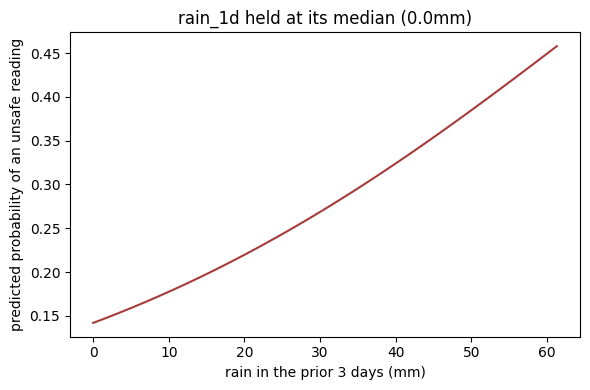

In [8]:
rain_1d_fixed = model_df["rain_1d"].median()
rain_3d_grid = np.linspace(model_df["rain_3d"].min(), model_df["rain_3d"].quantile(0.99), 100)

grid = pd.DataFrame({"rain_1d": rain_1d_fixed, "rain_3d": rain_3d_grid})
grid_s = scaler.transform(grid)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    grid["predicted_probability"] = clf.predict_proba(grid_s)[:, 1]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(grid["rain_3d"], grid["predicted_probability"], color="#a53b3b")
ax.set_xlabel("rain in the prior 3 days (mm)")
ax.set_ylabel("predicted probability of an unsafe reading")
ax.set_title(f"rain_1d held at its median ({rain_1d_fixed:.1f}mm)")
plt.tight_layout()
plt.show()

## Part 8. Save the fitted formula

The coefficients and the scaler's mean/scale, so the live site (or a notebook for another city) can compute a prediction from a new rainfall reading without refitting the model from scratch.

In [9]:
import json

model_params = {
    "features": features,
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "coefficients": clf.coef_[0].tolist(),
    "intercept": clf.intercept_[0],
    "threshold_eColi": 100,
    "trained_on": "Toronto, 2007-2026, TORONTO CITY station (climate ID 6158355)",
    "test_auc": float(roc_auc_score(y_test, proba)),
}

with open("../data/precip_model.json", "w") as f:
    json.dump(model_params, f, indent=2)

print("saved to ../data/precip_model.json")
model_params

saved to ../data/precip_model.json


{'features': ['rain_1d', 'rain_3d'],
 'scaler_mean': [2.5136575616255827, 7.740559626915391],
 'scaler_scale': [7.375492396303619, 13.637608596858719],
 'coefficients': [0.15778224361517307, 0.36294395163498716],
 'intercept': np.float64(-1.5398859567684609),
 'threshold_eColi': 100,
 'trained_on': 'Toronto, 2007-2026, TORONTO CITY station (climate ID 6158355)',
 'test_auc': 0.6497144649105433}